# EDA: Image Analysis

## Setup

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import kx
import polars as pl
from tqdm import tqdm

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
MASK_DIR = DATA_DIR / "HAM10000_segmentations_lesion_tschandl"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

SEED = 0
CLASSES = ["nv", "mel", "bkl", "bcc", "akiec", "vasc", "df"]

In [3]:
image_paths = pl.DataFrame(
    [
        {"image_id": path.stem, "image_path": str(path)}
        for image_dir in IMAGE_DIRS
        for path in sorted(image_dir.glob("ISIC_*.jpg"))
    ]
)
metadata = (
    pl.read_csv(METADATA_PATH)
    .join(image_paths, on="image_id", how="left", validate="1:1")
    .with_columns(
        (pl.lit(f"{MASK_DIR}/") + pl.col("image_id") + pl.lit("_segmentation.png")).alias("mask_path"),
        pl.col("dx").cast(pl.Enum(CLASSES)),
    )
)

assert metadata.height == 10_015
assert metadata["image_path"].null_count() == 0
assert all(Path(path).exists() for path in metadata["mask_path"])

In [4]:
train = metadata

print(f"Images: {train.height:,} | Lesions: {train['lesion_id'].n_unique():,}")
train["dx"].value_counts().sort("dx")

Images: 10,015 | Lesions: 7,470


dx,count
enum,u32
"""nv""",6705
"""mel""",1113
"""bkl""",1099
"""bcc""",514
"""akiec""",327
"""vasc""",142
"""df""",115


## 1. Visual overview

### 1.1 Per-class sample grids

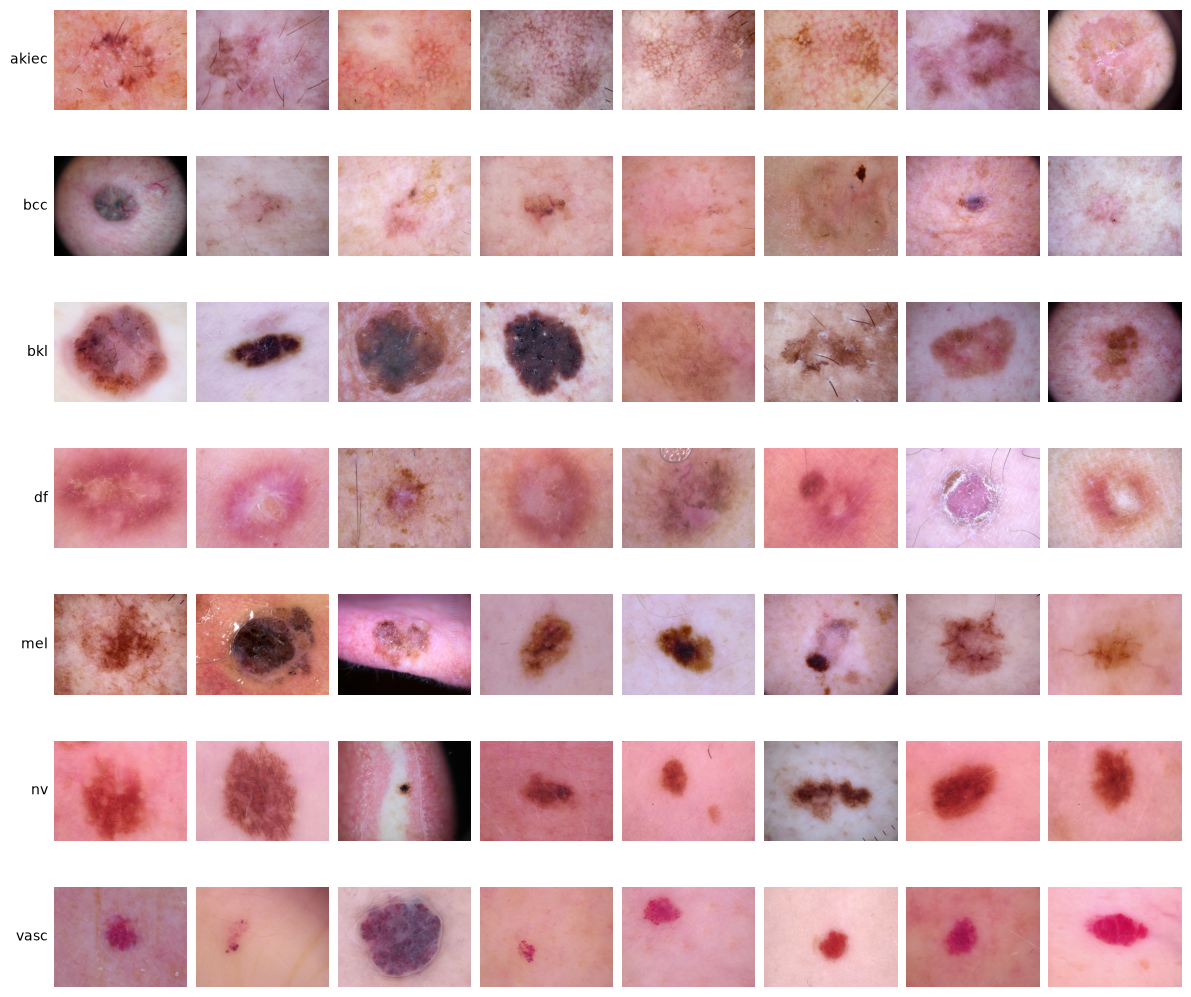

In [5]:
samples = train.unique("lesion_id", keep="first", maintain_order=True)

kx.plot(
    samples["image_path"].to_list(),
    samples["dx"].cast(pl.String).to_list(),
    "imgrid",
    n=8,
    seed=SEED,
    interpolation="antialiased",
);

### 1.2 Variation between images of the same lesion

In [6]:
train.filter(pl.len().over("lesion_id") > 1)

lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,image_path,mask_path
str,str,enum,str,f64,str,str,str,str,str
"""HAM_0000118""","""ISIC_0027419""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0000118""","""ISIC_0025030""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0002730""","""ISIC_0026769""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0002730""","""ISIC_0025661""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0001466""","""ISIC_0031633""","""bkl""","""histo""",75.0,"""male""","""ear""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
…,…,…,…,…,…,…,…,…,…
"""HAM_0002867""","""ISIC_0033084""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0002867""","""ISIC_0033550""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"
"""HAM_0002867""","""ISIC_0033536""","""akiec""","""histo""",40.0,"""male""","""abdomen""","""vidir_modern""","""/home/vhrabar/Programing/lesio…","""/home/vhrabar/Programing/lesio…"


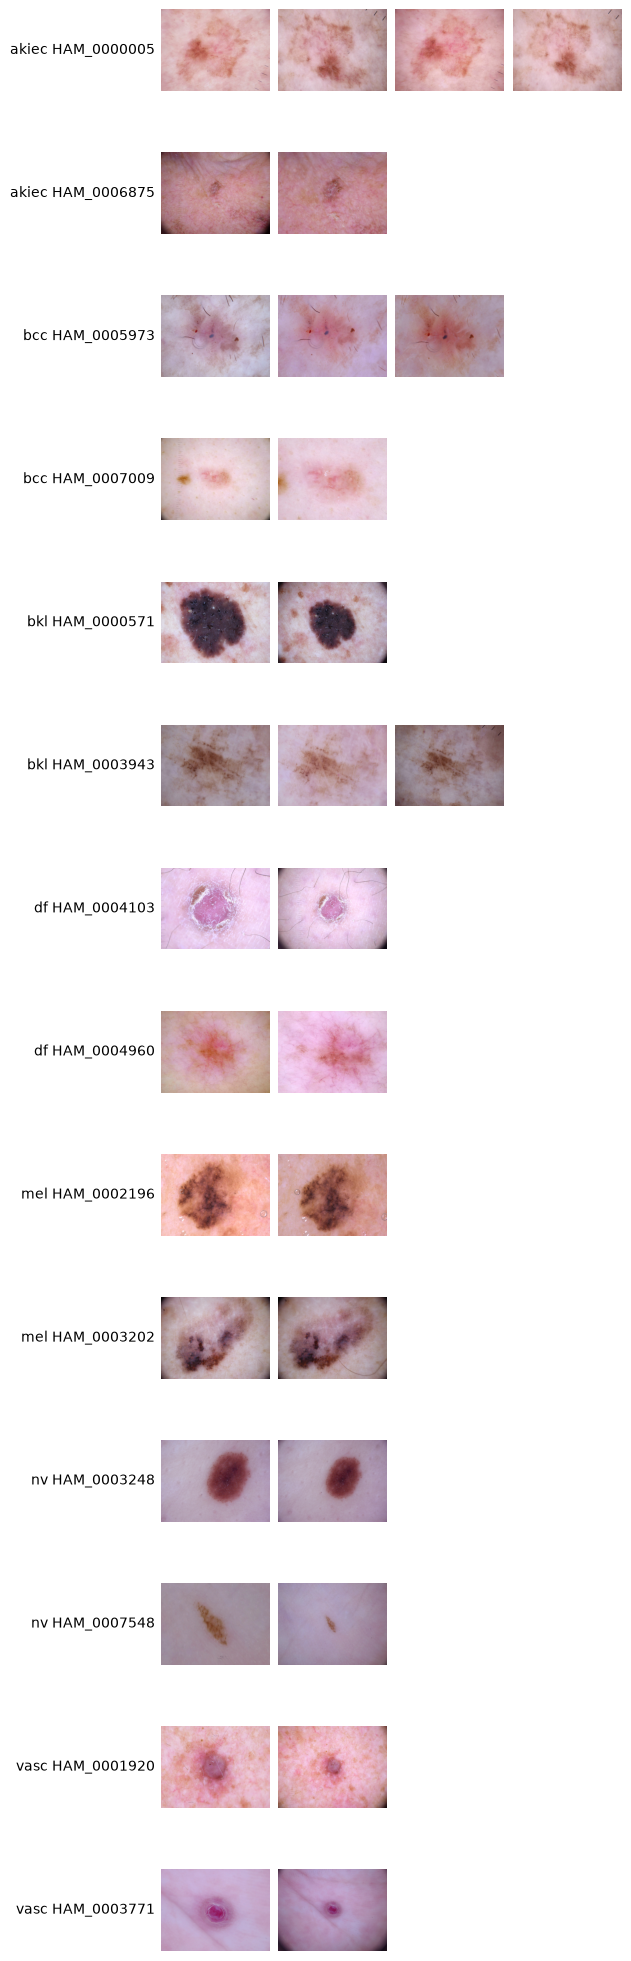

In [7]:
multi_image = train.filter(pl.len().over("lesion_id") > 1)
lesions = (
    multi_image.unique("lesion_id", keep="first", maintain_order=True)
    .filter(pl.int_range(pl.len()).shuffle(seed=SEED).over("dx") < 2)
    .select("lesion_id")
)
lesion_images = multi_image.join(lesions, on="lesion_id", maintain_order="left").with_columns(
    pl.concat_str(pl.col("dx").cast(pl.String), "lesion_id", separator=" ").alias("label")
)

kx.plot(
    lesion_images["image_path"].to_list(),
    lesion_images["label"].to_list(),
    "imgrid",
    n=4,
    seed=SEED,
    interpolation="antialiased",
);

## 2. Pixel statistics

In [8]:
FEATURES_PATH = ROOT / "output" / "eda" / "image_features.parquet"
COLOUR = {"mean_r": "Red", "mean_g": "Green", "mean_b": "Blue"}
APPEARANCE = {"brightness": "Brightness", "contrast": "Contrast", "saturation": "Saturation"}


def image_features(path: str) -> dict[str, float]:
    bgr = cv2.resize(cv2.imread(path), (224, 224), interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    grey = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    return {
        "mean_r": bgr[..., 2].mean() / 255,
        "mean_g": bgr[..., 1].mean() / 255,
        "mean_b": bgr[..., 0].mean() / 255,
        "brightness": hsv[..., 2].mean() / 255,
        "contrast": grey.std() / 255,
        "saturation": hsv[..., 1].mean() / 255,
    }


if FEATURES_PATH.exists():
    pixel_features = pl.read_parquet(FEATURES_PATH)
else:
    paths = train["image_path"].to_list()
    with ThreadPoolExecutor() as pool:
        rows = list(tqdm(pool.map(image_features, paths), total=len(paths)))
    pixel_features = pl.DataFrame(rows).with_columns(train["image_id"])
    FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
    pixel_features.write_parquet(FEATURES_PATH)

features = train.join(pixel_features, on="image_id", validate="1:1")


def plot_measures(measures: dict[str, str], group: str, data: pl.DataFrame = features, prefix: str = "") -> None:
    labels = data[group].cast(pl.String).to_list()
    for ax, (column, title) in zip(kx.grid(len(measures)), measures.items(), strict=True):
        kx.plot(data[column].to_numpy(), spec="box-rot", by=labels, ax=ax, title=f"{prefix}{title}", showfliers=False)
        ax.set_xlabel("")


def median_table(measures: dict[str, str], *groups: str) -> pl.DataFrame:
    return features.group_by(groups).agg(pl.len().alias("images"), pl.col(*measures).median().round(3)).sort(groups)

### 2.1 Colour by class

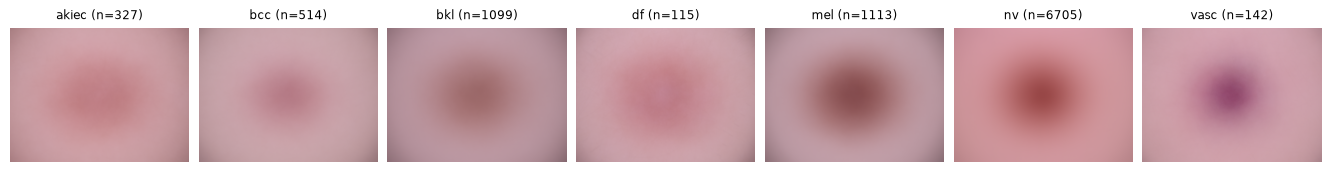

In [9]:
sample_paths = train["image_path"].to_list()
sample_labels = train["dx"].cast(pl.String).to_list()

kx.plot(sample_paths, sample_labels, "meanimg", interpolation="antialiased");

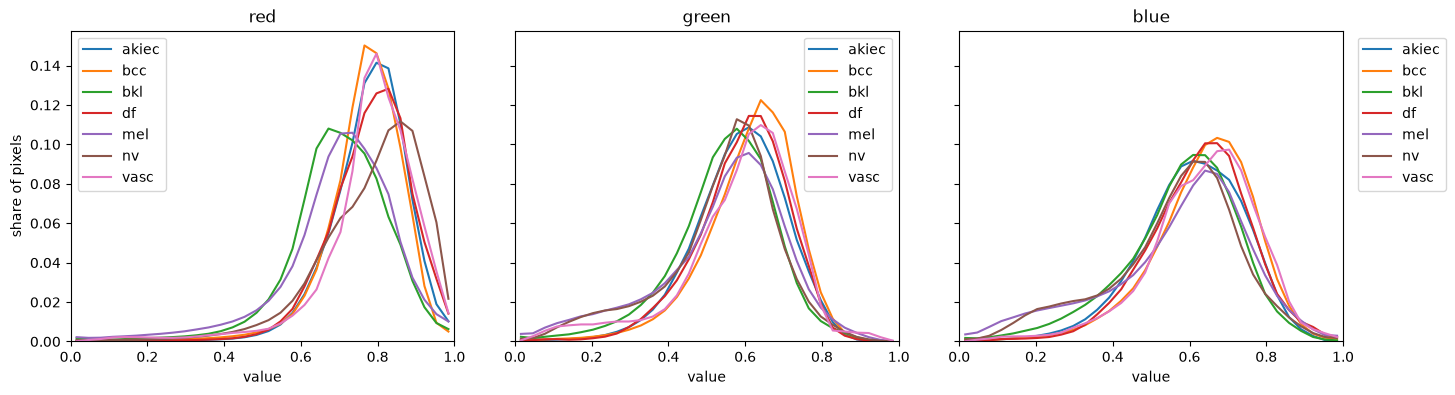

In [10]:
kx.plot(sample_paths, sample_labels, "colorhist-leg");

dx,images,mean_r,mean_g,mean_b
enum,u32,f64,f64,f64
"""nv""",6705,0.798,0.538,0.56
"""mel""",1113,0.694,0.538,0.567
"""bkl""",1099,0.691,0.546,0.577
"""bcc""",514,0.769,0.612,0.639
"""akiec""",327,0.78,0.584,0.6
"""vasc""",142,0.772,0.596,0.639
"""df""",115,0.791,0.594,0.626


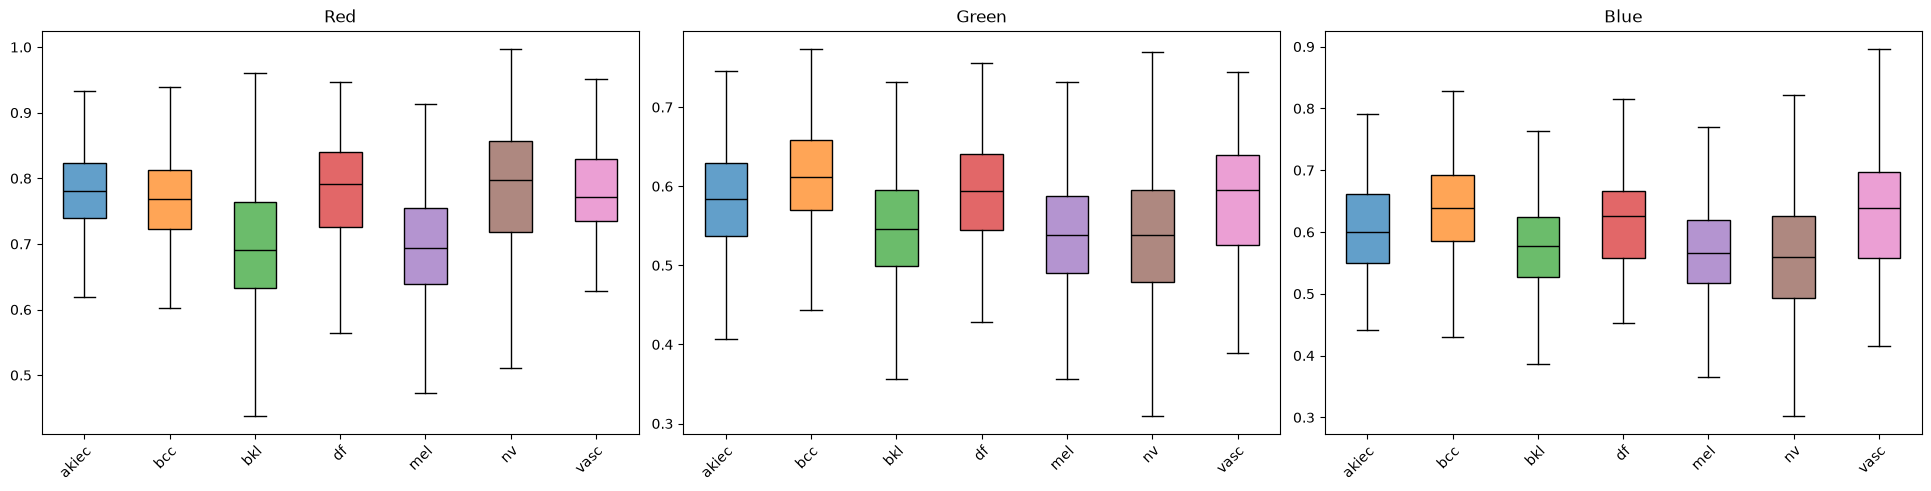

In [11]:
plot_measures(COLOUR, "dx")
median_table(COLOUR, "dx")

### 2.2 Brightness, contrast and saturation by class

dx,images,brightness,contrast,saturation
enum,u32,f64,f64,f64
"""nv""",6705,0.799,0.103,0.36
"""mel""",1113,0.697,0.126,0.25
"""bkl""",1099,0.694,0.09,0.226
"""bcc""",514,0.77,0.077,0.215
"""akiec""",327,0.78,0.084,0.264
"""vasc""",142,0.776,0.091,0.249
"""df""",115,0.792,0.077,0.245


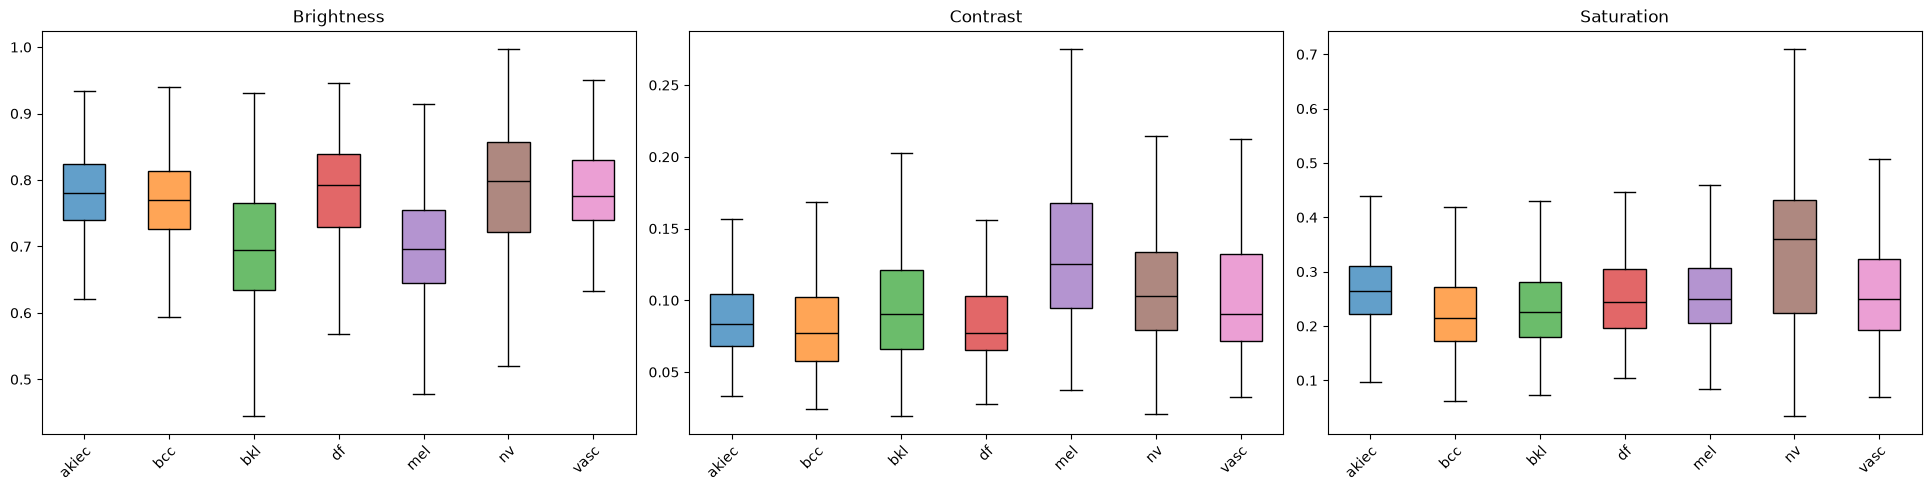

In [12]:
plot_measures(APPEARANCE, "dx")
median_table(APPEARANCE, "dx")

### 2.3 Brightness, contrast and saturation by source

dataset,images,brightness,contrast,saturation
str,u32,f64,f64,f64
"""rosendahl""",2259,0.751,0.088,0.227
"""vidir_modern""",3363,0.693,0.115,0.211
"""vidir_molemax""",3954,0.839,0.096,0.42
"""vienna_dias""",439,0.753,0.144,0.32


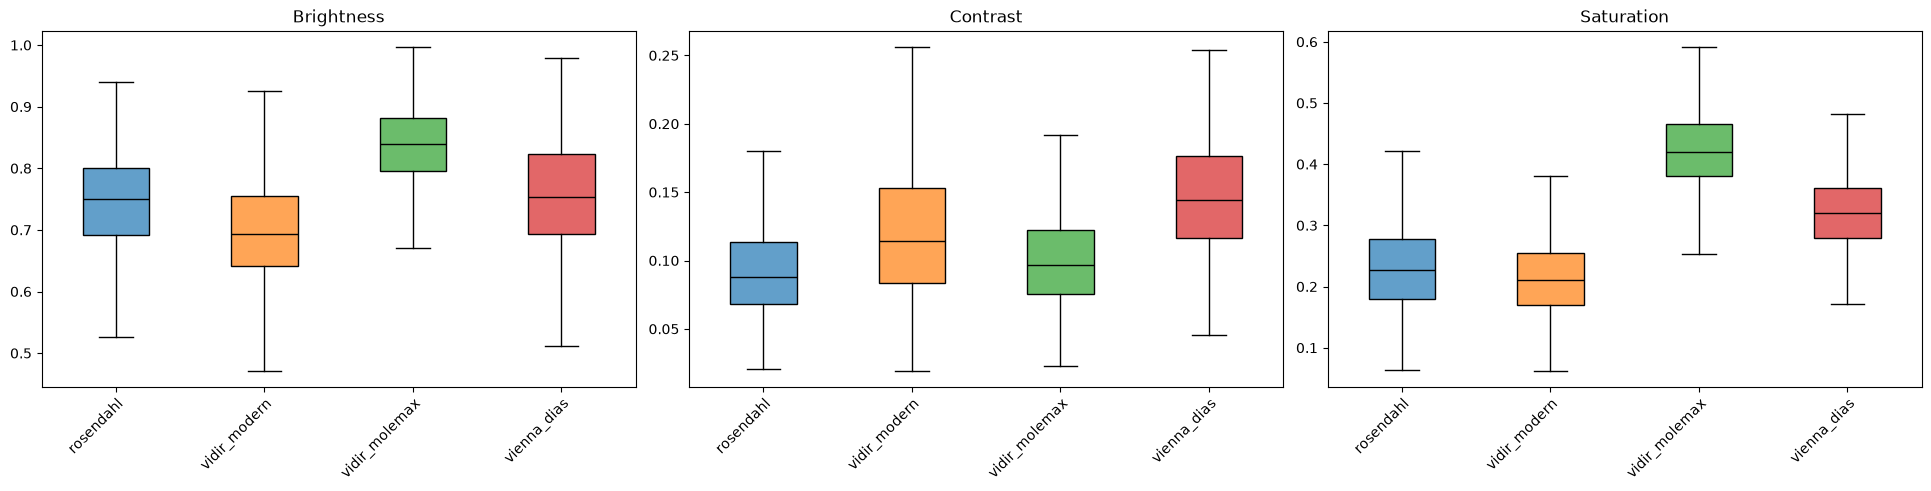

In [13]:
plot_measures(APPEARANCE, "dataset")
median_table(APPEARANCE, "dataset")

dataset,dx,images,brightness,contrast,saturation
str,enum,u32,f64,f64,f64
"""rosendahl""","""nv""",803,0.75,0.095,0.21
"""rosendahl""","""mel""",342,0.742,0.102,0.262
"""vidir_modern""","""nv""",1832,0.695,0.115,0.198
"""vidir_modern""","""mel""",680,0.675,0.13,0.235
"""vidir_molemax""","""nv""",3720,0.841,0.097,0.423
"""vidir_molemax""","""mel""",24,0.793,0.153,0.387
"""vienna_dias""","""nv""",350,0.768,0.14,0.313
"""vienna_dias""","""mel""",67,0.682,0.174,0.337


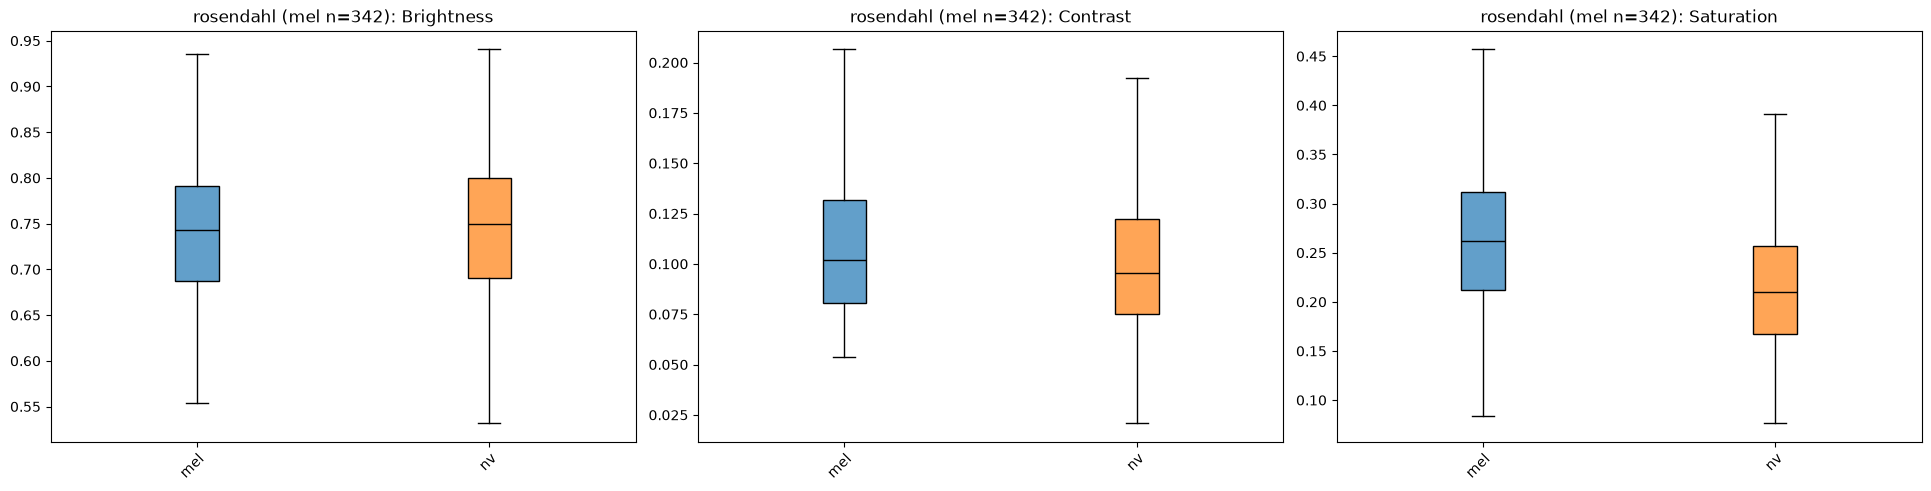

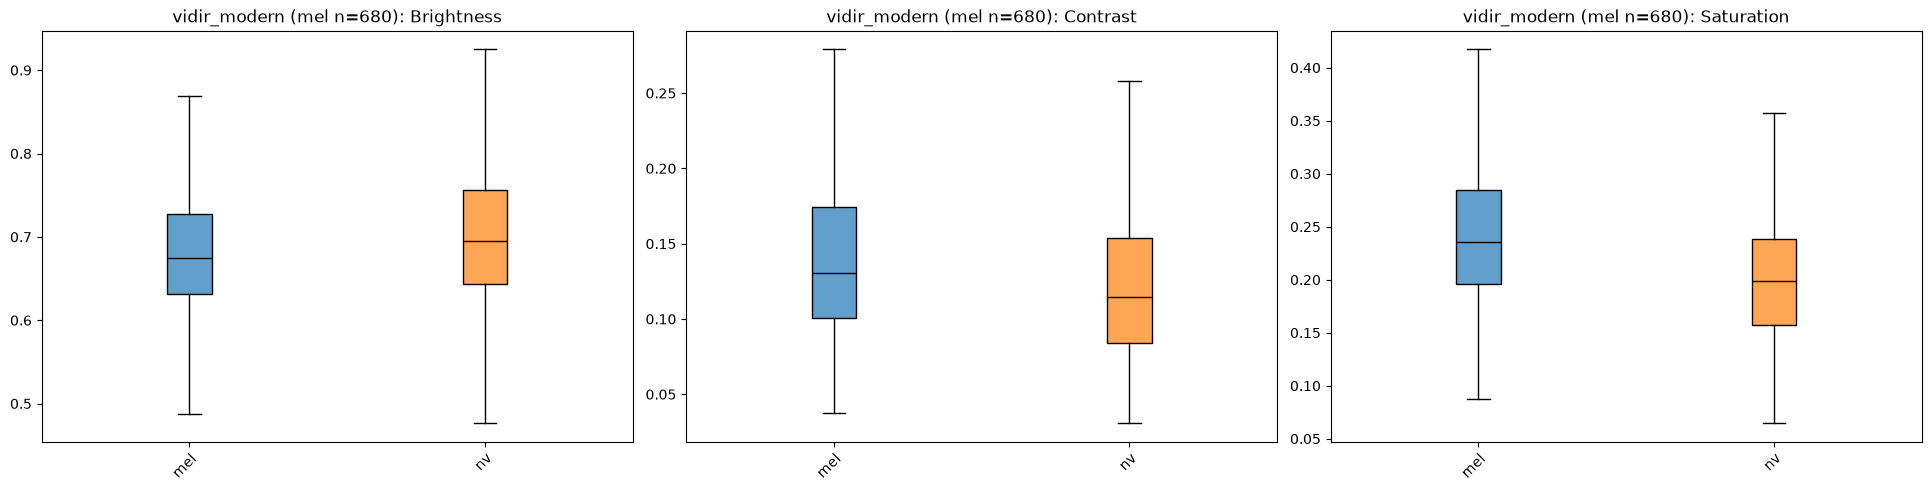

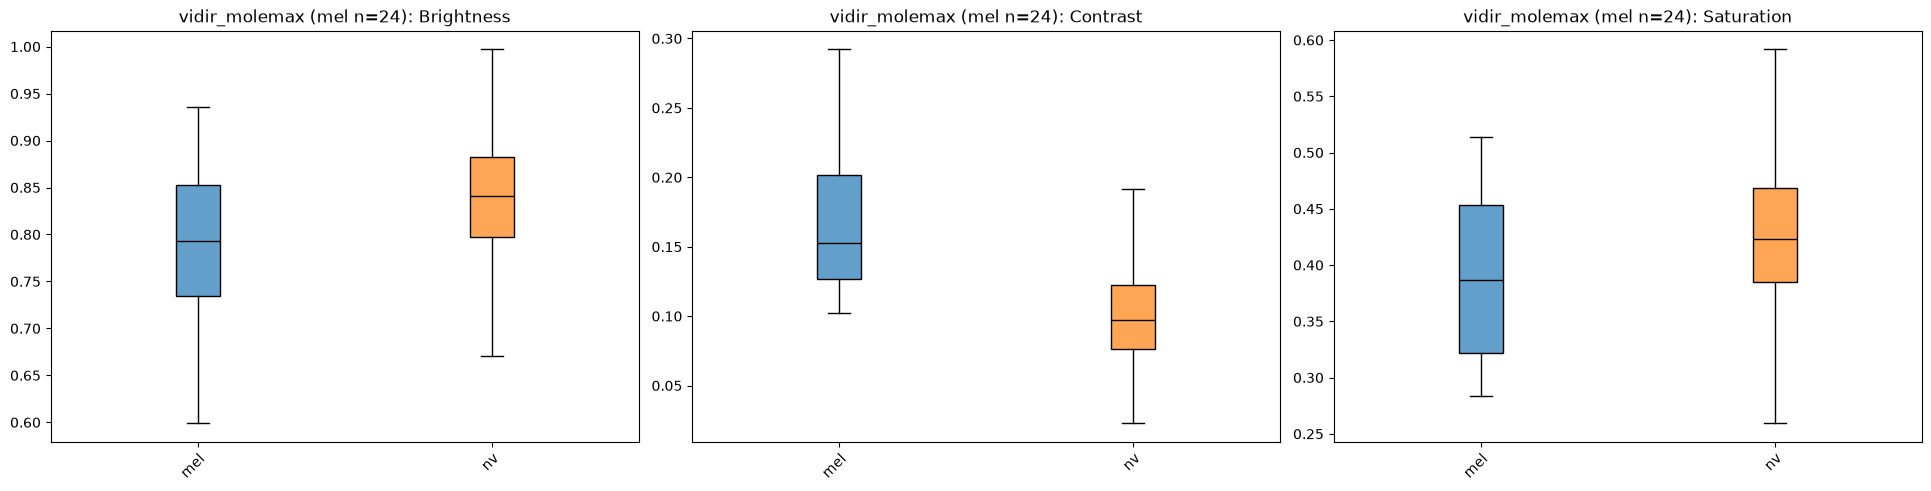

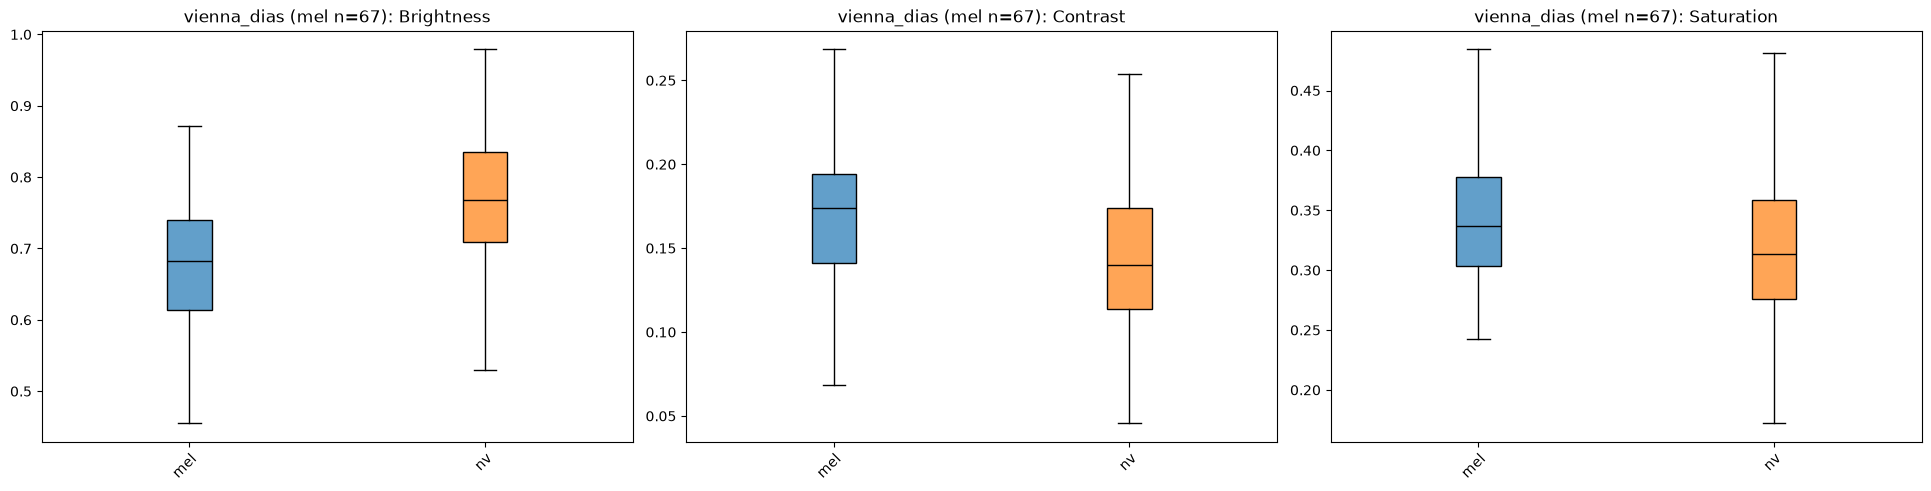

In [15]:
for src in features["dataset"].unique().sort():
    src_df = features.filter((pl.col("dataset") == src) & pl.col("dx").is_in(["mel", "nv"]))
    n_mel = src_df.filter(pl.col("dx") == "mel").height
    plot_measures(APPEARANCE, "dx", src_df, prefix=f"{src} (mel n={n_mel}): ")

median_table(APPEARANCE, "dataset", "dx").filter(pl.col("dx").is_in(["mel", "nv"]))

## 3. Normalisation

### 3.1 Mean and std on HAM10000 train

### 3.2 Comparison with ImageNet

### 3.3 Recommendation and config export

## 4. Image quality

### 4.1 Sharpness

### 4.2 Exposure

### 4.3 Outlier review

## 5. Artefacts

### 5.1 Dark corner detector

### 5.2 Hair detector

### 5.3 Prevalence by class and site

## 6. Lesion vs surrounding skin

### 6.1 Colour by class

### 6.2 Contrast by class